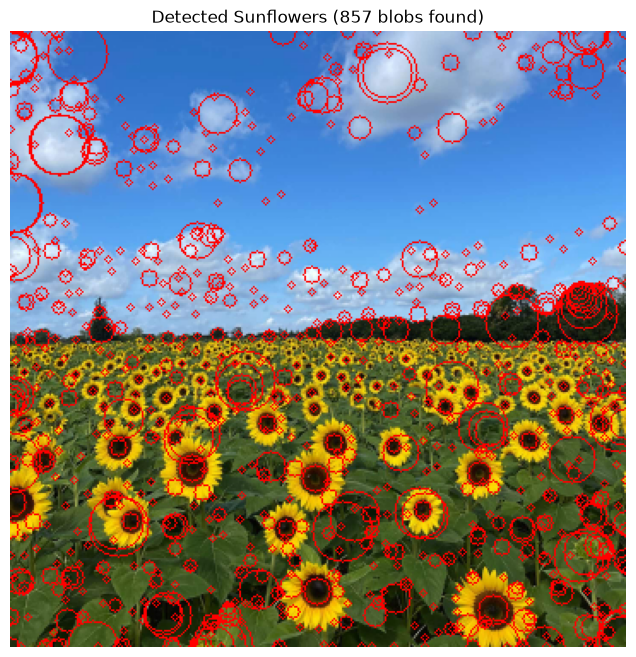

In [45]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the image as specified in the assignment[cite: 1]
im = cv.imread(
    'images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4
)

# Keep the original color image for drawing, and convert to grayscale for LoG detection
im_gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)
im_float = im_gray.astype(np.float32) / 255.0

# Define sigma range
min_sigma = 2.0
max_sigma = 13.0
num_sigmas = 12
sigmas = np.linspace(min_sigma, max_sigma, num_sigmas)

# Initialize scale-space volume (H, W, num_sigmas)
h, w = im_float.shape
scale_space = np.zeros((h, w, len(sigmas)), dtype=np.float32)

# Build scale-space volume using scale-normalized Laplacian of Gaussian
for i, sigma in enumerate(sigmas):
    ksize = int(2 * np.ceil(3 * sigma) + 1)
    # Ensure kernel size is odd
    if ksize % 2 == 0:
        ksize += 1
    blurred = cv.GaussianBlur(im_float, (ksize, ksize), sigmaX=sigma, sigmaY=sigma)
    laplacian = cv.Laplacian(blurred, cv.CV_32F, ksize=3)
    scale_space[:, :, i] = (sigma**2) * np.abs(laplacian)

# Extract local maxima (blobs) across 3D scale-space (y, x, scale)
blobs = []
threshold = 0.02 * np.max(scale_space)  # Adjusted relative threshold

for i, sigma in enumerate(sigmas):
    slice_curr = scale_space[:, :, i]

    # Find local maxima in the 2D spatial plane using OpenCV morphology dilation
    ksize_morph = int(2 * round(2 * sigma) + 1)
    if ksize_morph % 2 == 0:
        ksize_morph += 1
    kernel = cv.getStructuringElement(cv.MORPH_RECT, (ksize_morph, ksize_morph))
    local_max_xy = cv.dilate(slice_curr, kernel)

    # Get neighboring scales for 3D scale-space comparison
    upper = (scale_space[:, :, i + 1] if i < len(sigmas) - 1 else np.zeros_like(slice_curr))
    lower = scale_space[:, :, i - 1] if i > 0 else np.zeros_like(slice_curr)

    is_max = (
        (slice_curr == local_max_xy)
        & (slice_curr >= upper)
        & (slice_curr >= lower)
        & (slice_curr > threshold)
    )

    y_idxs, x_idxs = np.nonzero(is_max)
    for y, x in zip(y_idxs, x_idxs):
        blobs.append((y, x, sigma))

# Draw circles on a copy of the original color image (OpenCV uses BGR natively)
output_img_bgr = im.copy()

for y, x, sigma in blobs:
    # Radius formula for LoG blob detection: r = sigma * sqrt(2)
    radius = int(sigma * np.sqrt(2))
    cv.circle(output_img_bgr, (x, y), radius, (0, 0, 255), 1)  # Yellow circle (BGR)

# Convert the final output image to RGB format as requested
output_img_rgb = cv.cvtColor(output_img_bgr, cv.COLOR_BGR2RGB)

# Display using matplotlib
plt.figure(figsize=(12, 8))
plt.imshow(output_img_rgb)
plt.axis('off')
plt.title(f'Detected Sunflowers ({len(blobs)} blobs found)')
plt.show()